# Data Profiling Notebook

## 1. Setup & Libraries

In [1]:
# Libraries
import pandas as pd
import numpy as np

import matplotlib.pyplot as plt
import seaborn as sns
sns.set_theme(style="whitegrid", palette="muted", font="sans-serif")

# Configuration
pd.set_option('display.max_columns', None)      
pd.set_option('display.max_rows', 50)          
pd.set_option('display.min_rows', 20)           

pd.set_option('display.max_colwidth', None)      
pd.set_option('display.float_format', '{:,.2f}'.format) 

pd.set_option('display.width', 1000)

## 2. Data Loading

In [2]:
raw_df = pd.read_csv("../data/raw/HR-Employee-Attrition.csv")
print(f"Dataframe shape: {raw_df.shape}")
raw_df.head(10)

Dataframe shape: (1470, 35)


,Age,Attrition,BusinessTravel,DailyRate,Department,DistanceFromHome,Education,EducationField,EmployeeCount,EmployeeNumber,EnvironmentSatisfaction,Gender,HourlyRate,JobInvolvement,JobLevel,JobRole,JobSatisfaction,MaritalStatus,MonthlyIncome,MonthlyRate,NumCompaniesWorked,Over18,OverTime,PercentSalaryHike,PerformanceRating,RelationshipSatisfaction,StandardHours,StockOptionLevel,TotalWorkingYears,TrainingTimesLastYear,WorkLifeBalance,YearsAtCompany,YearsInCurrentRole,YearsSinceLastPromotion,YearsWithCurrManager
0,41,Yes,Travel_Rarely,1102,Sales,1,2,Life Sciences,1,1,2,Female,94,3,2,Sales Executive,4,Single,5993,19479,8,Y,Yes,11,3,1,80,0,8,0,1,6,4,0,5
1,49,No,Travel_Frequently,279,Research & Development,8,1,Life Sciences,1,2,3,Male,61,2,2,Research Scientist,2,Married,5130,24907,1,Y,No,23,4,4,80,1,10,3,3,10,7,1,7
2,37,Yes,Travel_Rarely,1373,Research & Development,2,2,Other,1,4,4,Male,92,2,1,Laboratory Technician,3,Single,2090,2396,6,Y,Yes,15,3,2,80,0,7,3,3,0,0,0,0
3,33,No,Travel_Frequently,1392,Research & Development,3,4,Life Sciences,1,5,4,Female,56,3,1,Research Scientist,3,Married,2909,23159,1,Y,Yes,11,3,3,80,0,8,3,3,8,7,3,0
4,27,No,Travel_Rarely,591,Research & Development,2,1,Medical,1,7,1,Male,40,3,1,Laboratory Technician,2,Married,3468,16632,9,Y,No,12,3,4,80,1,6,3,3,2,2,2,2
5,32,No,Travel_Frequently,1005,Research & Development,2,2,Life Sciences,1,8,4,Male,79,3,1,Laboratory Technician,4,Single,3068,11864,0,Y,No,13,3,3,80,0,8,2,2,7,7,3,6
6,59,No,Travel_Rarely,1324,Research & Development,3,3,Medical,1,10,3,Female,81,4,1,Laboratory Technician,1,Married,2670,9964,4,Y,Yes,20,4,1,80,3,12,3,2,1,0,0,0
7,30,No,Travel_Rarely,1358,Research & Development,24,1,Life Sciences,1,11,4,Male,67,3,1,Laboratory Technician,3,Divorced,2693,13335,1,Y,No,22,4,2,80,1,1,2,3,1,0,0,0
8,38,No,Travel_Frequently,216,Research & Development,23,3,Life Sciences,1,12,4,Male,44,2,3,Manufacturing Director,3,Single,9526,8787,0,Y,No,21,4,2,80,0,10,2,3,9,7,1,8
9,36,No,Travel_Rarely,1299,Research & Development,27,3,Medical,1,13,3,Male,94,3,2,Healthcare Representative,3,Married,5237,16577,6,Y,No,13,3,2,80,2,17,3,2,7,7,7,7


## Data Quality Audit

In [3]:
print("--------- Data Quality Audit ---------")

print(f"Duplicated value count: {raw_df.duplicated(subset = 'EmployeeNumber').sum()}")
print(f"Missing value count: {raw_df.isna().sum().sum()}\n")

print(f"Dataset information:")
raw_df.info()
print()

print(f"Descriptive metrics:")
raw_df.describe()

--------- Data Quality Audit ---------
Duplicated value count: 0
Missing value count: 0

Dataset information:
<class 'pandas.DataFrame'>
RangeIndex: 1470 entries, 0 to 1469
Data columns (total 35 columns):
 #   Column                    Non-Null Count  Dtype
---  ------                    --------------  -----
 0   Age                       1470 non-null   int64
 1   Attrition                 1470 non-null   str  
 2   BusinessTravel            1470 non-null   str  
 3   DailyRate                 1470 non-null   int64
 4   Department                1470 non-null   str  
 5   DistanceFromHome          1470 non-null   int64
 6   Education                 1470 non-null   int64
 7   EducationField            1470 non-null   str  
 8   EmployeeCount             1470 non-null   int64
 9   EmployeeNumber            1470 non-null   int64
 10  EnvironmentSatisfaction   1470 non-null   int64
 11  Gender                    1470 non-null   str  
 12  HourlyRate                1470 non-null   int64

,Age,DailyRate,DistanceFromHome,Education,EmployeeCount,EmployeeNumber,EnvironmentSatisfaction,HourlyRate,JobInvolvement,JobLevel,JobSatisfaction,MonthlyIncome,MonthlyRate,NumCompaniesWorked,PercentSalaryHike,PerformanceRating,RelationshipSatisfaction,StandardHours,StockOptionLevel,TotalWorkingYears,TrainingTimesLastYear,WorkLifeBalance,YearsAtCompany,YearsInCurrentRole,YearsSinceLastPromotion,YearsWithCurrManager
count,"1,470.00","1,470.00","1,470.00","1,470.00","1,470.00","1,470.00","1,470.00","1,470.00","1,470.00","1,470.00","1,470.00","1,470.00","1,470.00","1,470.00","1,470.00","1,470.00","1,470.00","1,470.00","1,470.00","1,470.00","1,470.00","1,470.00","1,470.00","1,470.00","1,470.00","1,470.00"
mean,36.92,802.49,9.19,2.91,1.00,"1,024.87",2.72,65.89,2.73,2.06,2.73,"6,502.93","14,313.10",2.69,15.21,3.15,2.71,80.00,0.79,11.28,2.80,2.76,7.01,4.23,2.19,4.12
std,9.14,403.51,8.11,1.02,0.00,602.02,1.09,20.33,0.71,1.11,1.10,"4,707.96","7,117.79",2.50,3.66,0.36,1.08,0.00,0.85,7.78,1.29,0.71,6.13,3.62,3.22,3.57
min,18.00,102.00,1.00,1.00,1.00,1.00,1.00,30.00,1.00,1.00,1.00,"1,009.00","2,094.00",0.00,11.00,3.00,1.00,80.00,0.00,0.00,0.00,1.00,0.00,0.00,0.00,0.00
25%,30.00,465.00,2.00,2.00,1.00,491.25,2.00,48.00,2.00,1.00,2.00,"2,911.00","8,047.00",1.00,12.00,3.00,2.00,80.00,0.00,6.00,2.00,2.00,3.00,2.00,0.00,2.00
50%,36.00,802.00,7.00,3.00,1.00,"1,020.50",3.00,66.00,3.00,2.00,3.00,"4,919.00","14,235.50",2.00,14.00,3.00,3.00,80.00,1.00,10.00,3.00,3.00,5.00,3.00,1.00,3.00
75%,43.00,"1,157.00",14.00,4.00,1.00,"1,555.75",4.00,83.75,3.00,3.00,4.00,"8,379.00","20,461.50",4.00,18.00,3.00,4.00,80.00,1.00,15.00,3.00,3.00,9.00,7.00,3.00,7.00
max,60.00,"1,499.00",29.00,5.00,1.00,"2,068.00",4.00,100.00,4.00,5.00,4.00,"19,999.00","26,999.00",9.00,25.00,4.00,4.00,80.00,3.00,40.00,6.00,4.00,40.00,18.00,15.00,17.00


## Column formatting

In [4]:
# Column title format
raw_df.columns = raw_df.columns.str.strip()

# Drop meaningless columns for analysis
raw_df = raw_df.drop(columns = ["EmployeeCount", "StandardHours", "Over18", "EmployeeNumber", "MonthlyRate", "DailyRate", "HourlyRate"])
print(f"New shape: {raw_df.shape}")
print(f"Columns: {list(raw_df.columns)}")

New shape: (1470, 28)
Columns: ['Age', 'Attrition', 'BusinessTravel', 'Department', 'DistanceFromHome', 'Education', 'EducationField', 'EnvironmentSatisfaction', 'Gender', 'JobInvolvement', 'JobLevel', 'JobRole', 'JobSatisfaction', 'MaritalStatus', 'MonthlyIncome', 'NumCompaniesWorked', 'OverTime', 'PercentSalaryHike', 'PerformanceRating', 'RelationshipSatisfaction', 'StockOptionLevel', 'TotalWorkingYears', 'TrainingTimesLastYear', 'WorkLifeBalance', 'YearsAtCompany', 'YearsInCurrentRole', 'YearsSinceLastPromotion', 'YearsWithCurrManager']


## Dtype Formating

In [5]:
# Convert categorical values assigned as 'object' or 'int' dtypes
categories = [
    'Attrition',
    'BusinessTravel',
    'Department',
    'Education',
    'EducationField',
    'EnvironmentSatisfaction',
    'Gender',
    'JobInvolvement',
    'JobLevel',
    'JobRole',
    'JobSatisfaction',
    'MaritalStatus',
    'OverTime',
    'PerformanceRating',
    'RelationshipSatisfaction',
    'StockOptionLevel',
    'WorkLifeBalance',
    'TrainingTimesLastYear'
]

for cat in categories:
    raw_df[cat] = raw_df[cat].astype('category')

new_cats = list(raw_df.select_dtypes("category"))

# Remaining int64 variables remain the same
ints = list(raw_df.select_dtypes("int64"))

print("------- Processed dtypes audit --------")
print(f"Categorical variables ({len(new_cats)}) ----")
print(*new_cats, sep = "\n")
print()
print(f"Numerical variables ({len(ints)}) ----")
print(*ints, sep = "\n")

------- Processed dtypes audit --------
Categorical variables (18) ----
Attrition
BusinessTravel
Department
Education
EducationField
EnvironmentSatisfaction
Gender
JobInvolvement
JobLevel
JobRole
JobSatisfaction
MaritalStatus
OverTime
PerformanceRating
RelationshipSatisfaction
StockOptionLevel
TrainingTimesLastYear
WorkLifeBalance

Numerical variables (10) ----
Age
DistanceFromHome
MonthlyIncome
NumCompaniesWorked
PercentSalaryHike
TotalWorkingYears
YearsAtCompany
YearsInCurrentRole
YearsSinceLastPromotion
YearsWithCurrManager


## Categorical Unique Values

In [6]:
## Check categorical unique values
print(f"---- Categorical Unique Values Audit ----")
for cat in new_cats:
    print(raw_df[cat].value_counts().reset_index())
    print()

---- Categorical Unique Values Audit ----
  Attrition  count
0        No   1233
1       Yes    237

      BusinessTravel  count
0      Travel_Rarely   1043
1  Travel_Frequently    277
2         Non-Travel    150

               Department  count
0  Research & Development    961
1                   Sales    446
2         Human Resources     63

  Education  count
0         3    572
1         4    398
2         2    282
3         1    170
4         5     48

     EducationField  count
0     Life Sciences    606
1           Medical    464
2         Marketing    159
3  Technical Degree    132
4             Other     82
5   Human Resources     27

  EnvironmentSatisfaction  count
0                       3    453
1                       4    446
2                       2    287
3                       1    284

   Gender  count
0    Male    882
1  Female    588

  JobInvolvement  count
0              3    868
1              2    375
2              4    144
3              1     83

  JobLevel

## Check Numerical Domains

In [7]:
domain_pipeline = [
    ("Age", "Age >= 18", raw_df["Age"] >= 18),
    ("DistanceFromHome", "DistanceFromHome >= 0", raw_df["DistanceFromHome"] >= 0),
    (
        "Experience-related variables",
        "experience-related variables >= 0",
        raw_df[
            [
                "NumCompaniesWorked",
                "TotalWorkingYears",
                "YearsAtCompany",
                "YearsInCurrentRole",
                "YearsSinceLastPromotion",
                "YearsWithCurrManager",
            ]
        ].ge(0).all(axis=1),
    ),
    ("PercentSalaryHike", "PercentSalaryHike >= 0", raw_df["PercentSalaryHike"] >= 0),
]

domain_audit = pd.DataFrame(
    {
        "Feature group": [feature for feature, _, _ in domain_pipeline],
        "Rule": [rule for _, rule, _ in domain_pipeline],
        "Invalid count": [(~mask).sum() for _, _, mask in domain_pipeline],
    }
)

print("---- Numerical Domain Audit ----")
display(domain_audit)

invalid_domain_rows = pd.DataFrame(
    {
        feature: ~mask
        for feature, _, mask in domain_pipeline
    },
    index=raw_df.index,
)
invalid_domain_rows = raw_df.loc[invalid_domain_rows.any(axis=1)]
print(f"Invalid domain rows: {len(invalid_domain_rows)}")
display(invalid_domain_rows)


---- Numerical Domain Audit ----


,Feature group,Rule,Invalid count
0,Age,Age >= 18,0
1,DistanceFromHome,DistanceFromHome >= 0,0
2,Experience-related variables,experience-related variables >= 0,0
3,PercentSalaryHike,PercentSalaryHike >= 0,0


Invalid domain rows: 0


,Age,Attrition,BusinessTravel,Department,DistanceFromHome,Education,EducationField,EnvironmentSatisfaction,Gender,JobInvolvement,JobLevel,JobRole,JobSatisfaction,MaritalStatus,MonthlyIncome,NumCompaniesWorked,OverTime,PercentSalaryHike,PerformanceRating,RelationshipSatisfaction,StockOptionLevel,TotalWorkingYears,TrainingTimesLastYear,WorkLifeBalance,YearsAtCompany,YearsInCurrentRole,YearsSinceLastPromotion,YearsWithCurrManager


## Numerical Values Overview

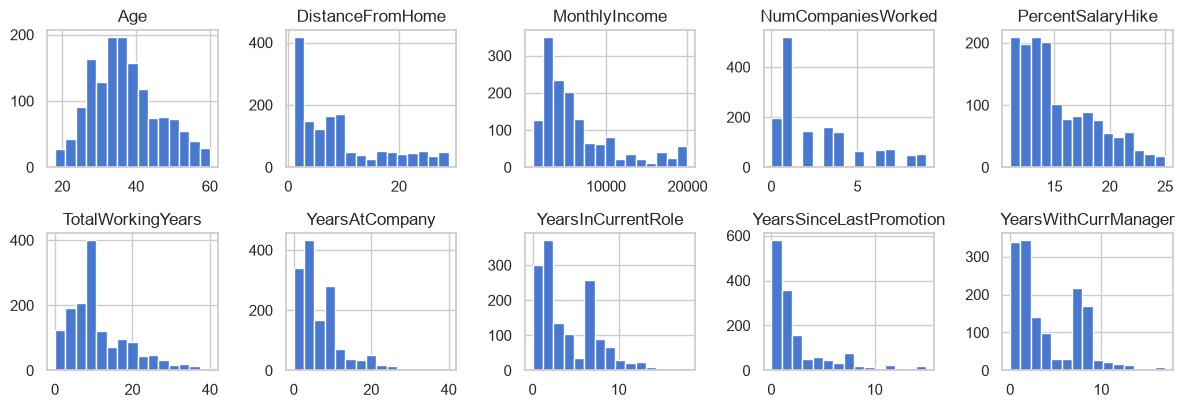

In [8]:
fig, axes = plt.subplots(ncols = 5, nrows = 3, figsize = (12, 6))
numeric_cols = ints  # 14 numeric columns in the dataset

# Flatten the 2D axes array so it matches the number of numerical columns
hist_axes = axes.ravel()

# Plot only the numeric columns, one histogram per axis
raw_df[numeric_cols].hist(ax=hist_axes[:len(numeric_cols)], bins=15)

# Hide any extra axis if present
for ax in hist_axes[len(numeric_cols):]:
    ax.set_visible(False)

plt.tight_layout()

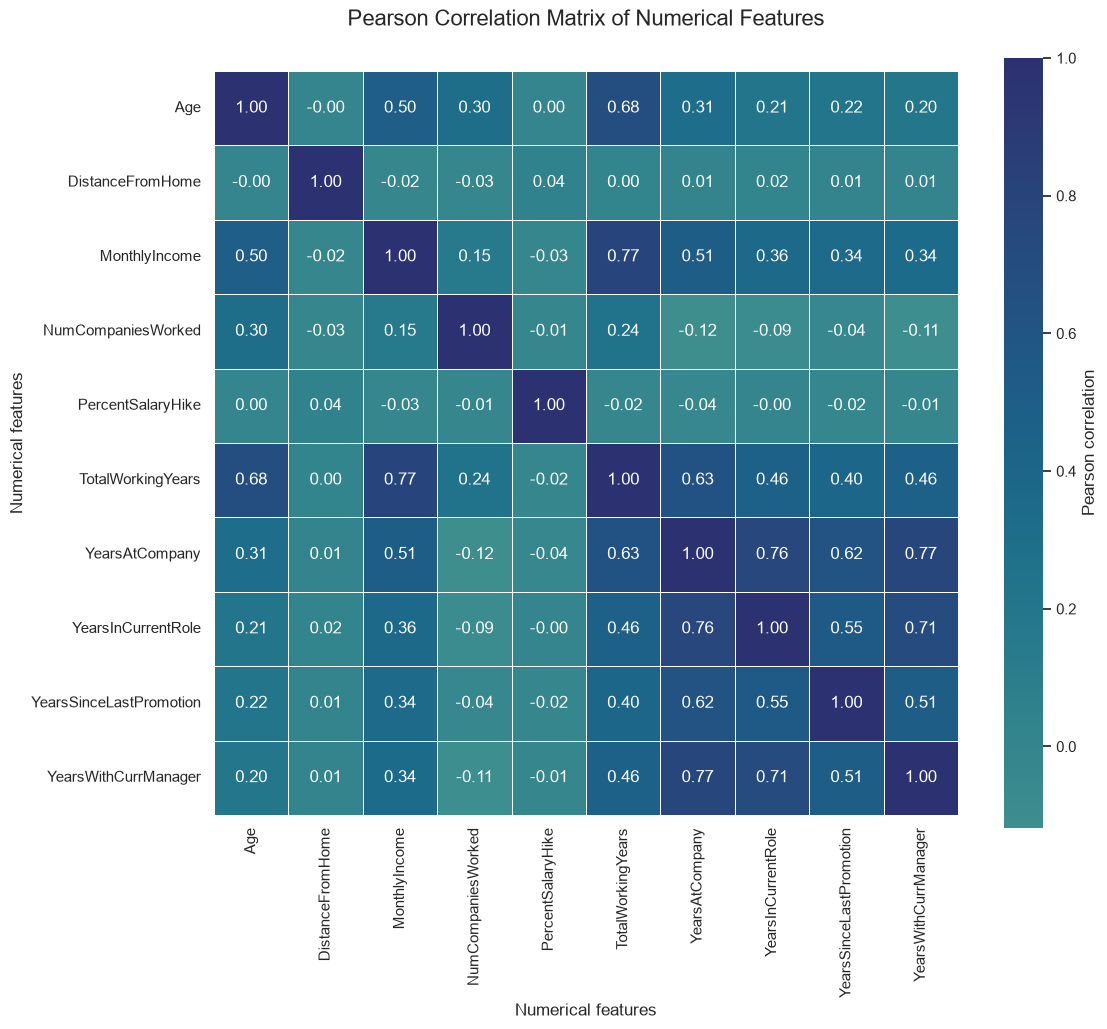

In [9]:
numeric_values = raw_df[ints]
corr_matrix2 = numeric_values.corr()

plt.figure(figsize=(12, 10))
sns.heatmap(
    corr_matrix2,
    annot=True,
    fmt=".2f",
    cmap="crest",
    center=0,
    linewidths=0.5,
    square=True,
    cbar_kws={"label": "Pearson correlation"}
)

plt.title("Pearson Correlation Matrix of Numerical Features", y=1.05, fontsize=16)
plt.xlabel("Numerical features")
plt.ylabel("Numerical features");

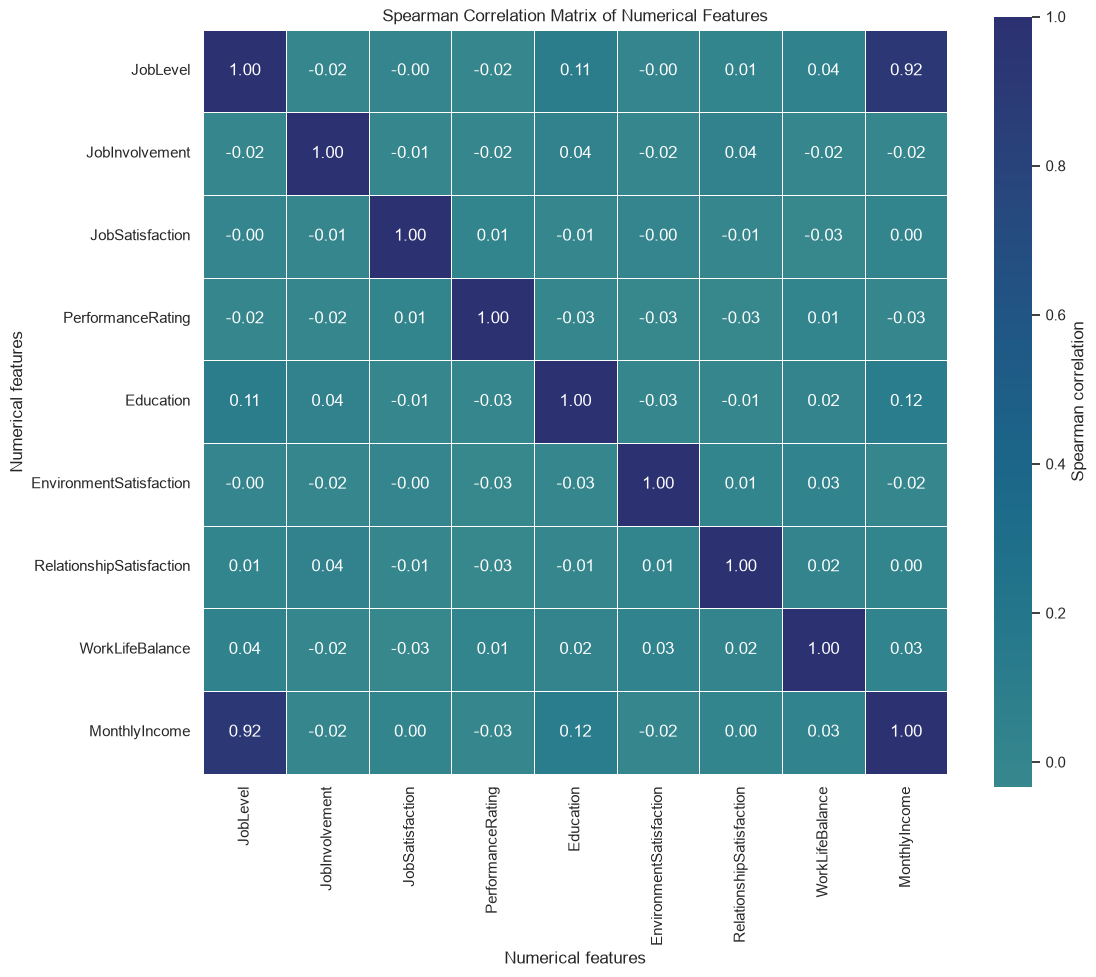

In [10]:
ordinal_cols = [
    "JobLevel",
    "JobInvolvement",
    "JobSatisfaction",
    "PerformanceRating",
    "Education",
    "EnvironmentSatisfaction",
    "RelationshipSatisfaction",
    "WorkLifeBalance"
]

corr_data = raw_df[ordinal_cols + ["MonthlyIncome"]]
corr_matrix = corr_data.corr(method="spearman")

plt.figure(figsize=(12, 10))
sns.heatmap(
    corr_matrix,
    annot=True,
    fmt=".2f",
    cmap="crest",
    center=0,
    linewidths=0.5,
    square=True,
    cbar_kws={"label": "Spearman correlation"}
)

plt.title("Spearman Correlation Matrix of Numerical Features")
plt.xlabel("Numerical features")
plt.ylabel("Numerical features");

In [11]:
continuous = ['Age', 'DailyRate', 'MonthlyIncome', 'MonthlyRate', 'HourlyRate' ]
num_df = pd.DataFrame()
num_df["Feature"] = ints
num_df["Continuous"] = num_df['Feature'].isin(continuous)
num_df["Skew"] = [raw_df[col].skew() for col in ints]

skew_levels = skew_levels = [
    'Highly Left Skewed',
    'Moderately Left Skewed',
    'Fairly Symmetrical',
    'Moderately Right Skewed',
    'Highly Right Skewed',
]
bins = [-np.inf, -1.0, -0.5, 0.5, 1.0, np.inf]
num_df['Skew Level'] = pd.cut(num_df['Skew'], bins = bins, labels = skew_levels)

def get_outliers(data, threshold = 1.5):
    outliers_dict = {}
    num_cols = list(data.select_dtypes('number').columns)
    for col in num_cols:
        q1 = data[col].quantile(0.25)
        q3 = data[col].quantile(0.75)
        iqr = q3 - q1
        lower_lim = q1 - iqr*threshold
        upper_lim = q3 + iqr*threshold
        outliers_dict[col] = (data[col] < lower_lim) | (data[col] > upper_lim)

    return outliers_dict

outliers_dict = get_outliers(raw_df)
num_df['Outlier Count (IQR)'] = [outliers_dict[col].sum() for col in outliers_dict]

num_df


,Feature,Continuous,Skew,Skew Level,Outlier Count (IQR)
0,Age,True,0.41,Fairly Symmetrical,0
1,DistanceFromHome,False,0.96,Moderately Right Skewed,0
2,MonthlyIncome,True,1.37,Highly Right Skewed,114
3,NumCompaniesWorked,False,1.03,Highly Right Skewed,52
4,PercentSalaryHike,False,0.82,Moderately Right Skewed,0
5,TotalWorkingYears,False,1.12,Highly Right Skewed,63
6,YearsAtCompany,False,1.76,Highly Right Skewed,104
7,YearsInCurrentRole,False,0.92,Moderately Right Skewed,21
8,YearsSinceLastPromotion,False,1.98,Highly Right Skewed,107
9,YearsWithCurrManager,False,0.83,Moderately Right Skewed,14


## Export Dataset

In [12]:
# Remove useless features for analysis and export clean dataset
raw_df.to_csv("../data/clean/clean_data.csv", index=False)